<a href="https://colab.research.google.com/github/srihanreddy/Quantum-Hackathon/blob/main/Hybrid_QC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid Quantum-Classical Multilayer Network
### Iris and Wine classification | Classical baseline vs. hybrid quantum-classical model

This notebook performs the complete experiment in stages:
1. Environment and reproducibility setup
2. Dataset exploration and preprocessing
3. Classical MLP baseline
4. Quantum circuit construction and inspection
5. Hybrid quantum-classical model training
6. Classification metrics and visualizations
7. Quantum resource and timing analysis
8. Exporting results for the project report

**Important:** This is a local quantum simulation using PennyLane `default.qubit`, not a run on physical quantum hardware. We do not assume quantum advantage; conclusions must follow the measured results.

## 0. Install dependencies (run once)

If packages are already installed in the active Jupyter environment, skip this cell. If you need to install, use the notebook's active Python interpreter via `%pip`.

To reduce disk usage, install without pip's download cache. PyTorch can be a large download, so ensure the drive holding your Python/Jupyter environment and temporary directory has enough free space.

In [1]:
%pip install --no-cache-dir numpy pandas scikit-learn matplotlib seaborn torch pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 127.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 129.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 139.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 206.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 118.0 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


## 1. Imports, configuration and reproducibility

In [2]:
import os, sys, json, time, math, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

import pennylane as qml
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, auc,
    classification_report
)
from IPython.display import display

SEED = 42
N_QUBITS = 4
N_Q_LAYERS = 2
SHOTS = 256
EPOCHS = 30
BATCH_SIZE = 16
LEARNING_RATE = 0.01
TEST_SIZE = 0.20

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(1)

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("Platform:", platform.platform())
print("Project/results directory:", RESULTS_DIR.resolve())
print("Device: CPU simulator (PennyLane default.qubit)")

Python: 3.13.16
PyTorch: 2.14.1+cu130
PennyLane: 0.45.1
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Project/results directory: /content/results
Device: CPU simulator (PennyLane default.qubit)


## 2. Load and explore Iris and Wine datasets

In [3]:
datasets = {
    "Iris": load_iris(),
    "Wine": load_wine()
}

for name, ds in datasets.items():
    print(f"\\n{name}:")
    print("Samples:", ds.data.shape[0])
    print("Features:", ds.data.shape[1])
    print("Classes:", list(ds.target_names))
    print("Class counts:", dict(zip(*np.unique(ds.target, return_counts=True))))
    display(pd.DataFrame(ds.data, columns=ds.feature_names).head())

\nIris:
Samples: 150
Features: 4
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Class counts: {np.int64(0): np.int64(50), np.int64(1): np.int64(50), np.int64(2): np.int64(50)}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


\nWine:
Samples: 178
Features: 13
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class counts: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Preprocessing

Both datasets are split using stratification (80% train, 20% test). Standardization and PCA are fitted **only on the training set** to prevent data leakage. PCA maps both datasets to four features so they can be encoded on four qubits.

For Iris, PCA is not strictly needed because it already has four features, but applying the same preprocessing pipeline keeps the model input interface consistent.

In [4]:
def prepare_dataset(dataset_name):
    ds = datasets[dataset_name]
    X_train, X_test, y_train, y_test = train_test_split(
        ds.data, ds.target,
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=ds.target
    )

    preprocessing = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=N_QUBITS, random_state=SEED))
    ])

    X_train_p = preprocessing.fit_transform(X_train).astype(np.float32)
    X_test_p = preprocessing.transform(X_test).astype(np.float32)

    return {
        "X_train": X_train_p,
        "X_test": X_test_p,
        "y_train": y_train.astype(np.int64),
        "y_test": y_test.astype(np.int64),
        "class_names": list(ds.target_names),
        "preprocessing": preprocessing,
        "original_feature_names": ds.feature_names
    }

prepared = {name: prepare_dataset(name) for name in datasets}

for name, d in prepared.items():
    print(name, "| train:", d["X_train"].shape, "| test:", d["X_test"].shape)

Iris | train: (120, 4) | test: (30, 4)
Wine | train: (142, 4) | test: (36, 4)


## 4. Model definitions: classical MLP and hybrid quantum-classical network

In [5]:
def build_quantum_qnode(shots=None):
    dev = qml.device("default.qubit", wires=N_QUBITS, shots=shots)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

    return circuit

weight_shapes = {"weights": (N_Q_LAYERS, N_QUBITS, 3)}

class ClassicalMLP(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(N_QUBITS, 16), nn.ReLU(),
            nn.Linear(16, 8), nn.ReLU(),
            nn.Linear(8, n_classes)
        )

    def forward(self, x):
        return self.network(x)

class HybridQuantumClassical(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.pre = nn.Sequential(
            nn.Linear(N_QUBITS, 8), nn.Tanh(),
            nn.Linear(8, N_QUBITS)
        )
        self.quantum = qml.qnn.TorchLayer(build_quantum_qnode(shots=None), weight_shapes)
        self.post = nn.Sequential(
            nn.Linear(N_QUBITS, 8), nn.ReLU(),
            nn.Linear(8, n_classes)
        )

    def encoded_features(self, x):
        return torch.pi * torch.tanh(self.pre(x))

    def forward(self, x):
        q_in = self.encoded_features(x)
        q_out = self.quantum(q_in)
        return self.post(q_out)

print("Classical and hybrid model classes defined.")
print("Qubits:", N_QUBITS, "| Variational layers:", N_Q_LAYERS)
print("Trainable quantum circuit parameters:", N_Q_LAYERS * N_QUBITS * 3)

Classical and hybrid model classes defined.
Qubits: 4 | Variational layers: 2
Trainable quantum circuit parameters: 24


## 5. Inspect the quantum circuit

In [6]:
example_circuit = build_quantum_qnode(shots=None)
example_inputs = torch.tensor([0.1, 0.2, 0.3, 0.4], dtype=torch.float32)
example_weights = torch.randn(N_Q_LAYERS, N_QUBITS, 3)

print(qml.draw(example_circuit)(example_inputs, example_weights))
try:
    spec = qml.specs(example_circuit)(example_inputs, example_weights)
    print("\\nPennyLane resource specification:")
    print(spec["resources"])
    print("Circuit depth reported by PennyLane:", spec["resources"].depth)
except Exception as e:
    print("Could not obtain device resource specification in this PennyLane version:", repr(e))

0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤  <Z>

M0 = 
tensor([0.1000, 0.2000, 0.3000, 0.4000])
M1 = 
tensor([[[ 1.9269,  1.4873,  0.9007],
         [-2.1055,  0.6784, -1.2345],
         [-0.0431, -1.6047,  0.3559],
         [-0.6866, -0.4934,  0.2415]],

        [[-1.1109,  0.0915, -2.3169],
         [-0.2168, -0.3097, -0.3957],
         [ 0.8034, -0.6216, -0.5920],
         [-0.0631, -0.8286,  0.3309]]])
\nPennyLane resource specification:
Wire allocations: 4
Total gates: 2
Gate counts:
- AngleEmbedding: 1
- StronglyEntanglingLayers: 1
Measurements:
- expval(PauliZ): 4
Depth: 2
Circuit depth reported by PennyLane: 2


## 6. Training and inference helper functions

The same training settings and train/test split are used for both models. Training uses analytic expectation values on the simulator so gradients can be computed efficiently. The finite-shot circuit pass is evaluated separately later.

In [7]:
def train_model(model, X_train, y_train, epochs=EPOCHS,
                batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE):
    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,
                        generator=generator)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    start = time.perf_counter()

    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(xb)
        history.append(epoch_loss / len(dataset))

    elapsed = time.perf_counter() - start
    return history, elapsed

def predict_probabilities(model, X):
    model.eval()
    start = time.perf_counter()
    with torch.no_grad():
        logits = model(torch.tensor(X, dtype=torch.float32))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
    elapsed = time.perf_counter() - start
    return probabilities, elapsed

def calculate_metrics(y_true, probabilities):
    y_pred = probabilities.argmax(axis=1)
    n_classes = probabilities.shape[1]
    y_bin = label_binarize(y_true, classes=np.arange(n_classes))
    try:
        macro_ovr_auc = roc_auc_score(
            y_bin, probabilities, average="macro"
        )
    except ValueError:
        macro_ovr_auc = np.nan

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "macro_ovr_auroc": macro_ovr_auc,
        "y_pred": y_pred,
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=np.arange(n_classes)
        )
    }

## 7. Train both models on both datasets

In [8]:
all_results = {}
metric_rows = []
training_histories = {}

for dataset_name, data in prepared.items():
    print(f"\\n========== {dataset_name.upper()} ==========")
    X_train, X_test = data["X_train"], data["X_test"]
    y_train, y_test = data["y_train"], data["y_test"]
    n_classes = len(data["class_names"])

    for model_name in ["Classical MLP", "Hybrid QC"]:
        # Reset seed before each model initialization for reproducibility.
        torch.manual_seed(SEED)
        np.random.seed(SEED)

        if model_name == "Classical MLP":
            model = ClassicalMLP(n_classes)
        else:
            model = HybridQuantumClassical(n_classes)

        history, train_seconds = train_model(model, X_train, y_train)
        probabilities, inference_seconds = predict_probabilities(model, X_test)
        metrics = calculate_metrics(y_test, probabilities)

        key = (dataset_name, model_name)
        all_results[key] = {
            "model": model,
            "probabilities": probabilities,
            "metrics": metrics,
            "training_seconds": train_seconds,
            "inference_seconds": inference_seconds
        }
        training_histories[key] = history

        metric_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "accuracy": metrics["accuracy"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "macro_f1": metrics["macro_f1"],
            "macro_ovr_auroc": metrics["macro_ovr_auroc"],
            "training_time_seconds": train_seconds,
            "inference_time_seconds": inference_seconds,
            "inference_time_per_sample_ms": inference_seconds / len(y_test) * 1000
        })

        print(f"{model_name}: accuracy={metrics['accuracy']:.4f}, "
              f"macro-F1={metrics['macro_f1']:.4f}, "
              f"train={train_seconds:.2f}s, inference={inference_seconds:.4f}s")

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

\n========== IRIS ==========
Classical MLP: accuracy=0.9667, macro-F1=0.9666, train=1.26s, inference=0.0016s
Hybrid QC: accuracy=0.9667, macro-F1=0.9666, train=9.91s, inference=0.0094s
\n========== WINE ==========
Classical MLP: accuracy=0.9722, macro-F1=0.9710, train=0.34s, inference=0.0002s
Hybrid QC: accuracy=0.9444, macro-F1=0.9407, train=5.41s, inference=0.0103s


,dataset,model,accuracy,balanced_accuracy,macro_f1,macro_ovr_auroc,training_time_seconds,inference_time_seconds,inference_time_per_sample_ms
0,Iris,Classical MLP,0.9667,0.9667,0.9666,1.0000,1.2593,0.0016,0.0538
1,Iris,Hybrid QC,0.9667,0.9667,0.9666,0.9967,9.9114,0.0094,0.3150
2,Wine,Classical MLP,0.9722,0.9667,0.9710,1.0000,0.3430,0.0002,0.0053
3,Wine,Hybrid QC,0.9444,0.9333,0.9407,1.0000,5.4107,0.0103,0.2875


## 8. Training curves

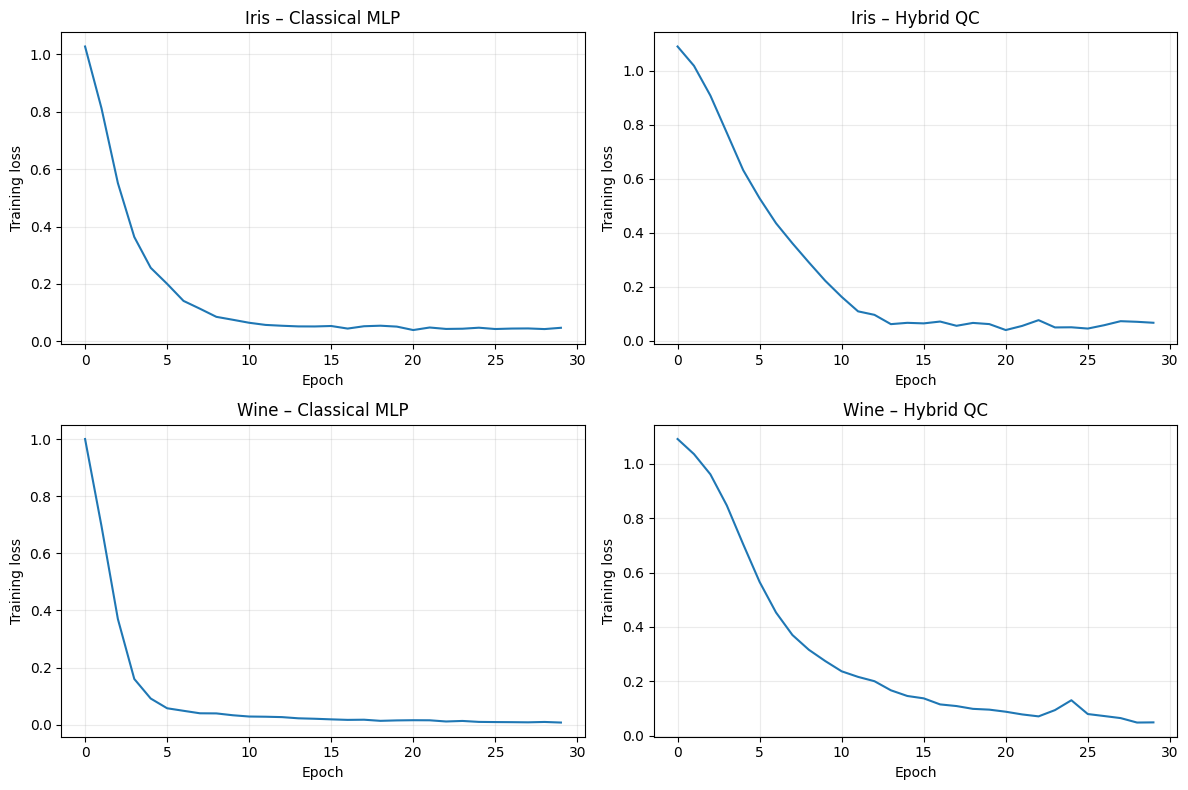

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (key, history) in zip(axes.ravel(), training_histories.items()):
    ax.plot(history)
    ax.set_title(f"{key[0]} – {key[1]}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")
    ax.grid(alpha=0.25)
plt.tight_layout()

plt.show()

## 9. Confusion matrices and classification reports

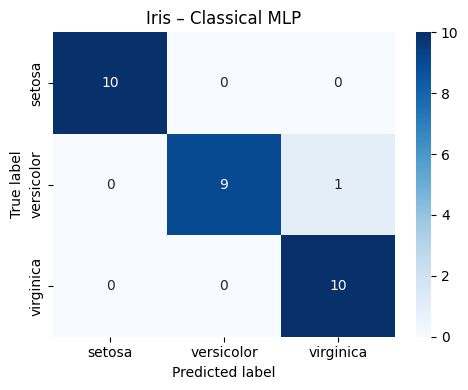

\nIris – Classical MLP
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



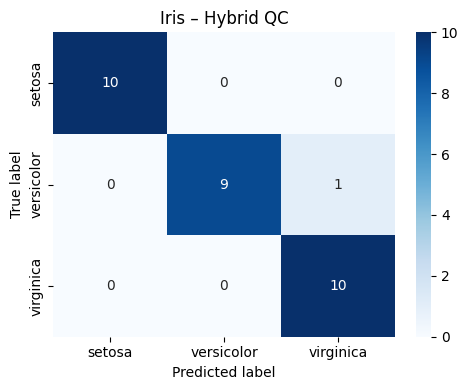

\nIris – Hybrid QC
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



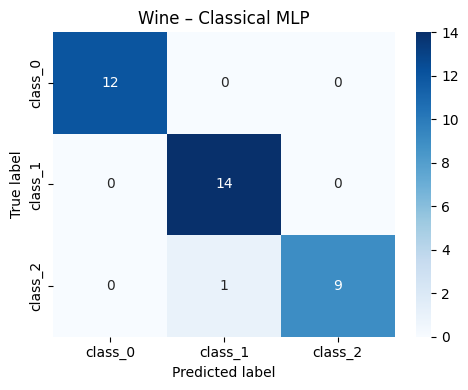

\nWine – Classical MLP
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



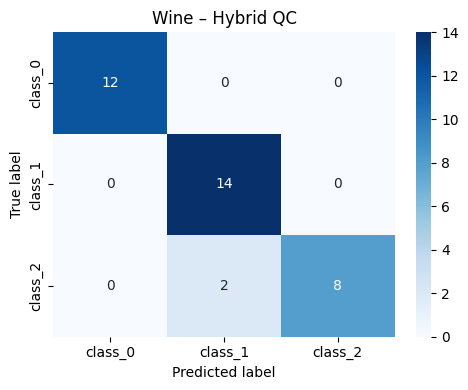

\nWine – Hybrid QC
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.80      0.89        10

    accuracy                           0.94        36
   macro avg       0.96      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



In [10]:
for dataset_name, data in prepared.items():
    for model_name in ["Classical MLP", "Hybrid QC"]:
        result = all_results[(dataset_name, model_name)]
        cm = result["metrics"]["confusion_matrix"]
        y_pred = result["metrics"]["y_pred"]

        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=data["class_names"],
                    yticklabels=data["class_names"])
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.title(f"{dataset_name} – {model_name}")
        plt.tight_layout()
        plt.show()

        print(f"\\n{dataset_name} – {model_name}")
        print(classification_report(
            data["y_test"], y_pred,
            target_names=data["class_names"], zero_division=0
        ))

## 10. ROC curves and AUROC (multiclass one-vs-rest)

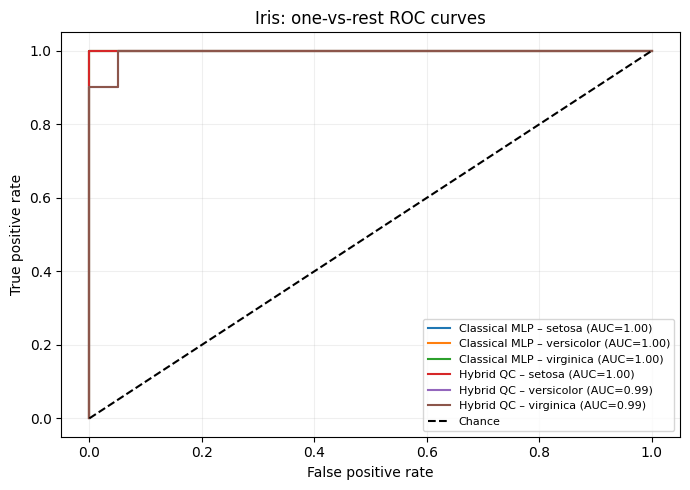

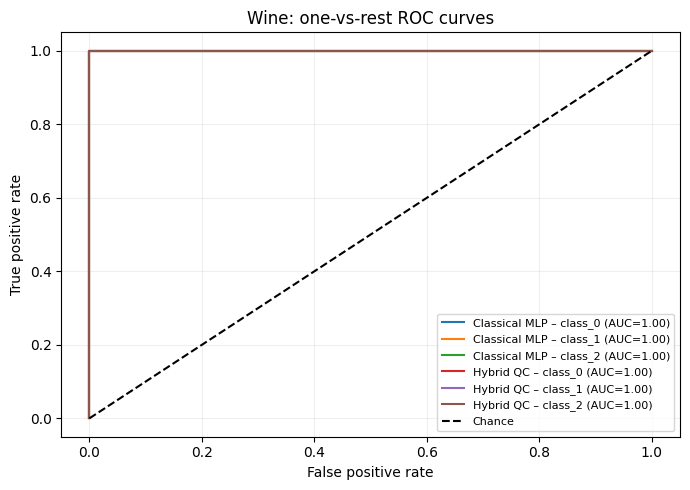

In [11]:
for dataset_name, data in prepared.items():
    y_true = data["y_test"]
    class_names = data["class_names"]
    y_bin = label_binarize(y_true, classes=np.arange(len(class_names)))

    plt.figure(figsize=(7, 5))
    for model_name in ["Classical MLP", "Hybrid QC"]:
        probs = all_results[(dataset_name, model_name)]["probabilities"]
        for class_idx, class_name in enumerate(class_names):
            fpr, tpr, _ = roc_curve(y_bin[:, class_idx], probs[:, class_idx])
            plt.plot(fpr, tpr, label=f"{model_name} – {class_name} (AUC={auc(fpr,tpr):.2f})")
    plt.plot([0, 1], [0, 1], "k--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{dataset_name}: one-vs-rest ROC curves")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

## 11. Quantum resource measurements

The notebook reports:
- Number of qubits and circuit parameters
- Circuit depth from PennyLane's resource specification (if supported by the installed version)
- Gate counts from the circuit tape when available
- Shots per measured circuit and total measured qubit outcomes
- Number of observed training forward batches (a practical circuit-call proxy)
- Finite-shot circuit inference time

Training uses analytic simulator backpropagation. Therefore, parameter-shift evaluations are **not** claimed as actual training executions. Circuit-call and gate counts are simulator-level measurements/estimates, not physical quantum hardware job counts.

In [12]:
def build_finite_shot_qnode(shots):
    dev = qml.device("default.qubit", wires=N_QUBITS, shots=shots)

    @qml.qnode(dev)
    def finite_circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    return finite_circuit

resource_rows = []
for dataset_name, data in prepared.items():
    model = all_results[(dataset_name, "Hybrid QC")]["model"]
    qnode = build_finite_shot_qnode(SHOTS)
    model.eval()

    with torch.no_grad():
        q_inputs = model.encoded_features(torch.tensor(data["X_test"], dtype=torch.float32)).numpy()
    q_weights = model.quantum.weights.detach().cpu().numpy()

    start = time.perf_counter()
    finite_quantum_outputs = np.asarray([qnode(row, q_weights) for row in q_inputs])
    finite_shot_seconds = time.perf_counter() - start

    # Get template resource information with the analytic circuit.
    analytic_qnode = build_quantum_qnode(shots=None)
    sample_input = torch.tensor(q_inputs[0], dtype=torch.float32)
    sample_weights = torch.tensor(q_weights, dtype=torch.float32)
    depth = np.nan
    gate_count = np.nan
    gate_types = "Unavailable"
    try:
        spec = qml.specs(analytic_qnode)(sample_input, sample_weights)
        depth = spec["resources"].depth
        gate_count = spec["resources"].num_gates
        gate_types = str(spec["resources"].gate_types)
    except Exception as exc:
        print("Resource introspection note:", exc)

    n_test = len(data["y_test"])
    resource_rows.append({
        "dataset": dataset_name,
        "qubits": N_QUBITS,
        "modes": "N/A – qubit simulator",
        "variational_layers": N_Q_LAYERS,
        "trainable_quantum_parameters": N_Q_LAYERS * N_QUBITS * 3,
        "circuit_depth": depth,
        "circuit_gate_count": gate_count,
        "gate_types": gate_types,
        "shots_per_sample": SHOTS,
        "test_samples_measured": n_test,
        "total_qubit_shot_outcomes": SHOTS * n_test * N_QUBITS,
        "training_forward_batch_calls_proxy": EPOCHS * math.ceil(len(data["y_train"]) / BATCH_SIZE),
        "finite_shot_quantum_inference_seconds": finite_shot_seconds,
        "finite_shot_quantum_inference_ms_per_sample": finite_shot_seconds / n_test * 1000
    })

resource_df = pd.DataFrame(resource_rows)
display(resource_df)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


,dataset,qubits,modes,variational_layers,trainable_quantum_parameters,circuit_depth,circuit_gate_count,gate_types,shots_per_sample,test_samples_measured,total_qubit_shot_outcomes,training_forward_batch_calls_proxy,finite_shot_quantum_inference_seconds,finite_shot_quantum_inference_ms_per_sample
0,Iris,4,N/A – qubit simulator,2,24,2,2,"{'AngleEmbedding': 1, 'StronglyEntanglingLayer...",256,30,30720,240,0.429901,14.330027
1,Wine,4,N/A – qubit simulator,2,24,2,2,"{'AngleEmbedding': 1, 'StronglyEntanglingLayer...",256,36,36864,270,0.435301,12.091694


## 12. Compare model performance

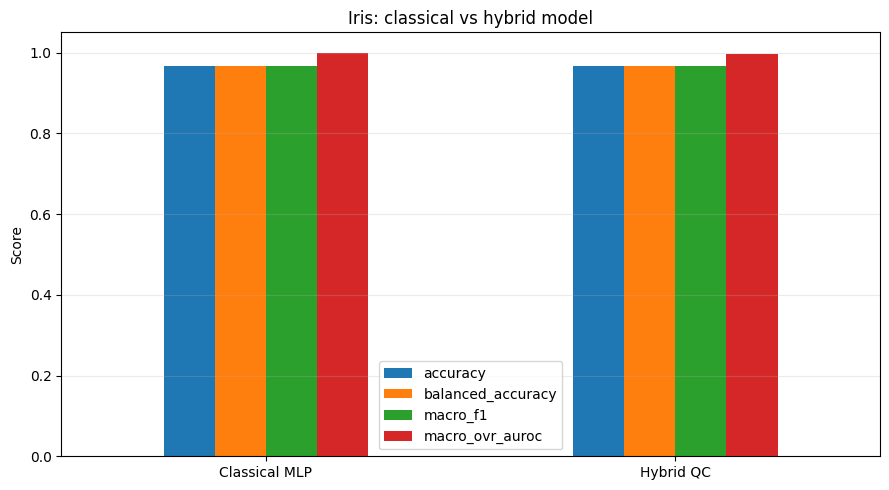

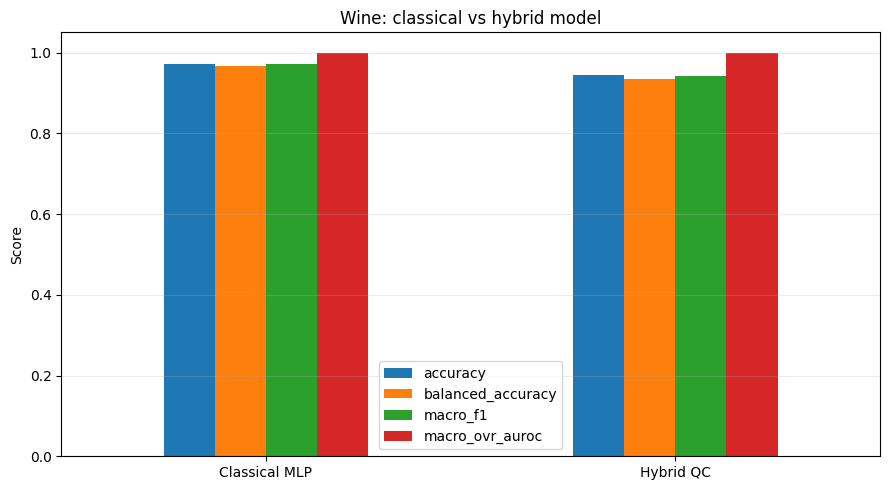

accuracy           balanced_accuracy                macro_f1  \
model   Classical MLP Hybrid QC     Classical MLP Hybrid QC Classical MLP   
dataset                                                                     
Iris           0.9667    0.9667            0.9667    0.9667        0.9666   
Wine           0.9722    0.9444            0.9667    0.9333        0.9710   

                  macro_ovr_auroc            
model   Hybrid QC   Classical MLP Hybrid QC  
dataset                                      
Iris       0.9666             1.0    0.9967  
Wine       0.9407             1.0    1.0000

In [13]:
for dataset_name in datasets:
    subset = metrics_df[metrics_df["dataset"] == dataset_name]
    ax = subset.set_index("model")[[
        "accuracy", "balanced_accuracy", "macro_f1", "macro_ovr_auroc"
    ]].plot(kind="bar", figsize=(9, 5), ylim=(0, 1.05))
    ax.set_title(f"{dataset_name}: classical vs hybrid model")
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

display(metrics_df.pivot(index="dataset", columns="model",
                         values=["accuracy", "balanced_accuracy", "macro_f1", "macro_ovr_auroc"]).round(4))

## 13. Export results

In [14]:
metrics_path = RESULTS_DIR / "metrics.csv"
resources_path = RESULTS_DIR / "quantum_resources.csv"
summary_path = RESULTS_DIR / "experiment_summary.json"

metrics_df.to_csv(metrics_path, index=False)
resource_df.to_csv(resources_path, index=False)

summary = {
    "seed": SEED,
    "test_size": TEST_SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "qubits": N_QUBITS,
    "variational_layers": N_Q_LAYERS,
    "shots": SHOTS,
    "simulator": "PennyLane default.qubit",
    "training_gradient_method": "analytic simulator backpropagation",
    "metrics": metrics_df.to_dict(orient="records"),
    "quantum_resources": resource_df.replace({np.nan: None}).to_dict(orient="records")
}
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print("Saved:")
print(metrics_path.resolve())
print(resources_path.resolve())
print(summary_path.resolve())

Saved:
/content/results/metrics.csv
/content/results/quantum_resources.csv
/content/results/experiment_summary.json


## 14. Report-ready interpretation guide

After running all cells, answer these questions using the tables and plots:

1. Which model achieved the highest accuracy on Iris?
2. Which model achieved the highest macro-F1 on Wine?
3. Does balanced accuracy tell the same story as ordinary accuracy?
4. Which classes are most frequently confused in each confusion matrix?
5. How do macro one-vs-rest AUROC values compare?
6. What is the hybrid model's training and inference overhead relative to the MLP?
7. What are the qubit count, circuit depth, shots and circuit parameter count?
8. Does the experiment show a predictive improvement that justifies the extra computational cost?

**Conclusion discipline:** A higher score on one small dataset is not evidence of quantum advantage. State clearly that this is a simulator-based proof-of-concept and discuss dataset size, simulator assumptions and resource overhead.